In [1]:
import matplotlib.pyplot as plt
import numpy as np
import typing

In [3]:
# class RandomVariable:
#     def __init__(self, name: str, expansion: typing.List[typing.Tuple[str, "RandomVariable"]]):
#         self.name = name
#         self.expansion = expansion
        
# OOG_tZ = RandomVariable(
#     name = "OOG_t(Z)",
#     expansion = [('+', "C[t+, su0, g, neq]"), ('+', "C[t+, lu0, g, neq]"), ('+', "C[t+, sd, g, neq]")]
# )

In [8]:
equations_df = [
    "OOG(t, Z) = C[t+, ll0, g, neq] + C[t+, lu0, g, neq]",
    "C[t+, ll0, g, neq] = C[t-, ll0, g, neq] - Delta[t, ll0, g, neq]",
    "C[t+, lu0, g, neq] = C[t-, lu0, g, neq] - Delta[t, lu0, g, neq]",
    
    # mai jos este S*_t sau SUM(Bin(z*[g+, 0] * W, 1/z*[g+, 0]), g+).
    "C[t-, ll0, g, neq] = C[t-1+, ll0, g, neq] + S*_t",
    "C[t-, ll0, g, =] = C[t-1+, ll0, g, =] + Bin(2q**2W, 1/(2q+1))",
    
    # mai jos este S_t sau SUM(Bin(z[g+, 0] * W, 1/z[g+, 0]), g+).
    "C[t-, lu0, g, neq] = C[t-1+, lu0, g, neq] + Delta[t-1, ll0, g, neq] + S_t",
    "C[t-, lu0, g, =] = C[t-1+, lu0, g, =] + Bin(qW, 1/(|G|-1)) + Bin(Delta[t-1, ll0, g, =], 1/q)",
    
    # "Delta[t, ll0, g, neq] = Hy(C[t-, ll0, g, neq], C[t-, ll0, g, =], 2qW)",
    "Delta[t, lu0, g, neq] = Hy(C[t-, lu0, g, neq], C[t-, lu0, g, =], W)",
]

equations_df = list(map(lambda eq: eq.split(" = "), equations_df))

In [4]:
equations = [
    "OOG(t, Z) = C[t+, su0, g, neq] + C[t+, lu0, g, neq] + C[t+, sd, g, neq]",
    "C[t+, su0, g, neq] = C[t-, su0, g, neq] - Delta[t, su0, g, neq]",
    "C[t+, lu0, g, neq] = C[t-, lu0, g, neq] - Delta[t, lu0, g, neq]",
    "C[t+, sd, g, neq] = C[t-, sd, g, neq] - Delta[t, sd, g, neq]",

    
    "C[t-1+, su0, g, neq] = C[t-1-, su0, g, neq] - Delta[t-1, su0, g, neq]",
    "C[t-1+, su0, g, =] = C[t-1-, su0, g, =] - Delta[t-1, su0, g, =]",
    "C[t-1+, lu0, g, neq] = C[t-1-, lu0, g, neq] - Delta[t-1, lu0, g, neq]",
    "C[t-1+, lu0, g, =] = C[t-1-, lu0, g, =] - Delta[t-1, lu0, g, =]",
    "C[t-1+, sd, g, neq] = C[t-1-, sd, g, neq] - Delta[t-1, sd, g, neq]",
    
    # mai jos este S_t sau SUM(Bin(z[g+, 0] * W, 1/z[g+, 0]), g+).
    "C[t-, su0, g, neq] = C[t-1+, su0, g, neq] + Delta[t-1, lu0, g, neq] + S_t",
    "C[t-, su0, g, =] = C[t-1+, su0, g, =] + Bin(Delta[t-1, lu0, g, =], 1/h)",
    
    "C[t-, lu0, g, neq] = C[t-1+, lu0, g, neq] + Delta[t, sd, g, neq]", # o sa se simplifice Delta[t, sd, g, neq].
    "C[t-, lu0, g, =] = C[t-1+, lu0, g, =] + Bin(h**2W, 1/h)",
    
    # mai jos este S*_t sau SUM(Bin(z*[g+, 0] * W, 1/z*[g+, 0]), g+).
    "C[t-, sd, g, neq] = C[t-1+, sd, g, neq] + S*_t",
    
    "Delta[t, su0, g, neq] = Hy(C[t-, su0, g, neq], C[t-, su0, g, =], W)",
    "Delta[t, lu0, g, neq] = Hy(C[t-, lu0, g, neq], C[t-, lu0, g, =], hW)",
    "Delta[t, sd, g, neq] = S*_t", #--asta sigur e corecta? da ptc poti elimina
                                   # mai mult decat primesti din sd queues.
]

equations = list(map(lambda eq: eq.split(" = "), equations))

In [5]:
def expand(e, equations):
    improve = True
    while improve:
        improve = False
        for rv, exp_rv in equations:
            if rv in e:
                improve = True
                e = e.replace(rv, exp_rv)
    return e

In [9]:
expand("OOG(t, Z)", equations_df)

'C[t-1+, ll0, g, neq] + S*_t - Delta[t, ll0, g, neq] + C[t-1+, lu0, g, neq] + Delta[t-1, ll0, g, neq] + S_t - Hy(C[t-1+, lu0, g, neq] + Delta[t-1, ll0, g, neq] + S_t, C[t-1+, lu0, g, =] + Bin(qW, 1/(|G|-1)) + Bin(Delta[t-1, ll0, g, =], 1/q), W)'

In [11]:
expand("C[t+, lu0, g, neq] + Delta[t, ll0, g, neq]", equations_df)

'C[t-1+, lu0, g, neq] + Delta[t-1, ll0, g, neq] + S_t - Hy(C[t-1+, lu0, g, neq] + Delta[t-1, ll0, g, neq] + S_t, C[t-1+, lu0, g, =] + Bin(qW, 1/(|G|-1)) + Bin(Delta[t-1, ll0, g, =], 1/q), W) + Delta[t, ll0, g, neq]'

In [12]:
expand("C[t+, lu0, g, =]", equations_df)

'C[t+, lu0, g, =]'

In [ ]:
A_t = C[t-1+, lu0, g, neq] + Delta[t-1, ll0, g, neq] =
    + A_t-1
    + S_t-1
    - Hy(
        C[t-1+, lu0, g, neq] + Delta[t-1, ll0, g, neq] + S_t,
        C[t-1+, lu0, g, =] + Bin(qW, 1/(|G|-1)) + Bin(Delta[t-1, ll0, g, =], 1/q),
        W
    )
    + Delta[t, ll0, g, neq] # = Hy(C[t-, ll0, g, neq], C[t-, ll0, g, =], 2qW)

In [ ]:
# df simplu:
B_t = C[t-, lu0, g, =]
    = C[t-1+, lu0, g, =] + Bin(qW, 1/(|G|-1)) + Bin(Delta[t-1, ll0, g, =], 1/q)
    = (C[t-1-, lu0, g, =] - Delta[t-1, lu0, g, =]) + Bin(qW, 1/(|G|-1)) + Bin(Delta[t-1, ll0, g, =], 1/q)
    = B_t-1 + Bin(qW, 1/(|G|-1)) + Bin(Delta[t-1, ll0, g, =], 1/q) - Delta[t-1, lu0, g, =]
    
# daca dem ca sum_t Bin(Delta[t, ll0, g, =], 1/q) >= sum_t Delta[t, lu0, g, =], e de ajuns ca sa arati ca B_t >= 0.
# trb sa expandezi DLU si mai ales DSU si sa vezi daca obtii echivalentul.

In [ ]:
OOG(t, Z) = OOG(t-1, Z) +
    + S_t
    + S*_t
    - Delta[t, ll0, g, neq]
    + Delta[t-1, ll0, g, neq]
    - Hy(
        C[t-1+, lu0, g, neq] + Delta[t-1, ll0, g, neq] + S_t,
        C[t-1+, lu0, g, =] + Bin(qW, 1/(|G|-1)) + Bin(Delta[t-1, ll0, g, =], 1/q),
        W
    )

In [30]:
expand("OOG(t, Z)", equations)

'C[t-1-, su0, g, neq] - Delta[t-1, su0, g, neq] + Delta[t-1, lu0, g, neq] + SUM(Bin(z[g+, 0] * W, 1/z[g+, 0]), g+) - Hy(C[t-1-, su0, g, neq] - Delta[t-1, su0, g, neq] + Delta[t-1, lu0, g, neq] + SUM(Bin(z[g+, 0] * W, 1/z[g+, 0]), g+), C[t-1-, su0, g, =] - Delta[t-1, su0, g, =] + Bin(Delta[t-1, lu0, g, =], 1/h), W) + C[t-1-, lu0, g, neq] - Delta[t-1, lu0, g, neq] + SUM(Bin(z*[g+, 0] * W, 1/z*[g+, 0]), g+) - Hy(C[t-1-, lu0, g, neq] - Delta[t-1, lu0, g, neq] + SUM(Bin(z*[g+, 0] * W, 1/z*[g+, 0]), g+), C[t-1+, lu0, g, =] + Bin(h**2W, 1/h), hW) + C[t-1-, sd, g, neq] - Delta[t-1, sd, g, neq] + SUM(Bin(z*[g+, 0] * W, 1/z*[g+, 0]), g+) - SUM(Bin(z*[g+, 0] * W, 1/z*[g+, 0]), g+)'

In [42]:
expand("C[t+, su0, g, neq]", equations)

'C[t-1-, su0, g, neq] - Delta[t-1, su0, g, neq] + Delta[t-1, lu0, g, neq] + SUM(Bin(z[g+, 0] * W, 1/z[g+, 0]), g+) - Hy(C[t-1-, su0, g, neq] - Delta[t-1, su0, g, neq] + Delta[t-1, lu0, g, neq] + SUM(Bin(z[g+, 0] * W, 1/z[g+, 0]), g+), C[t-1-, su0, g, =] - Delta[t-1, su0, g, =] + Bin(Delta[t-1, lu0, g, =], 1/h), W)'

In [44]:
expand("Delta[t, su0, g, neq]", equations)

'Hy(C[t-1-, su0, g, neq] - Delta[t-1, su0, g, neq] + Delta[t-1, lu0, g, neq] + SUM(Bin(z[g+, 0] * W, 1/z[g+, 0]), g+), C[t-1-, su0, g, =] - Delta[t-1, su0, g, =] + Bin(Delta[t-1, lu0, g, =], 1/h), W)'

In [5]:
expand("Delta[t, lu0, g, neq]", equations)

'Hy(C[t-1-, lu0, g, neq] - Delta[t-1, lu0, g, neq] + SUM(Bin(z*[g+, 0] * W, 1/z*[g+, 0]), g+), C[t-1-, lu0, g, =] - Delta[t-1, lu0, g, =] + Bin(h**2W, 1/h), hW)'

In [8]:
# A_t ~ C[t-1-, su0, g, neq] + Delta[t-1, lu0, g, neq] - Delta[t-1, su0, g, neq]
expand("C[t-, su0, g, neq] + Delta[t, lu0, g, neq] - Delta[t, su0, g, neq]", equations)

'C[t-1-, su0, g, neq] - Delta[t-1, su0, g, neq] + Delta[t-1, lu0, g, neq] + S_t + Hy(C[t-1-, lu0, g, neq] - Delta[t-1, lu0, g, neq] + S*_t, C[t-1-, lu0, g, =] - Delta[t-1, lu0, g, =] + Bin(h**2W, 1/h), hW) - Hy(C[t-1-, su0, g, neq] - Delta[t-1, su0, g, neq] + Delta[t-1, lu0, g, neq] + S_t, C[t-1-, su0, g, =] - Delta[t-1, su0, g, =] + Bin(Delta[t-1, lu0, g, =], 1/h), W)'

In [ ]:
# t-> t-1
# t-1 -> t-2
# A_t = ...
C[t-2-, su0, g, neq] + Delta[t-2, lu0, g, neq] - Delta[t-2, su0, g, neq] # = A_t-1
+ S_t-1
+ Hy(
    C[t-2-, lu0, g, neq] - Delta[t-2, lu0, g, neq] + S*_t-1
    C[t-2-, lu0, g, =] - Delta[t-2, lu0, g, =] + Bin(h**2W, 1/h),
    hW
)
- Hy(
    C[t-2-, su0, g, neq] - Delta[t-2, su0, g, neq] + Delta[t-2, lu0, g, neq] + S_t-1,
    C[t-2-, su0, g, =] - Delta[t-2, su0, g, =] + Bin(Delta[t-2, lu0, g, =], 1/h),
    W
)

In [10]:
# B_t ~ C[t-1-, su0, g, =] - Delta[t-1, su0, g, =] + Bin(Delta[t-1, lu0, g, =], 1/h)
expand("C[t-, su0, g, =] - Delta[t, su0, g, =] + Bin(Delta[t, lu0, g, =], 1/h)", equations)

'C[t-1-, su0, g, =] - Delta[t-1, su0, g, =] + Bin(Delta[t-1, lu0, g, =], 1/h) - Delta[t, su0, g, =] + Bin(Delta[t, lu0, g, =], 1/h)'

In [ ]:
# B_t = ...
C[t-2-, su0, g, =] - Delta[t-2, su0, g, =] + Bin(Delta[t-2, lu0, g, =], 1/h) # = B_t-1
- Delta[t-1, su0, g, =]
+ Bin(Delta[t-1, lu0, g, =], 1/h)

In [11]:
expand("C[t-, su0, g, neq]", equations)

'C[t-1-, su0, g, neq] - Delta[t-1, su0, g, neq] + Delta[t-1, lu0, g, neq] + S_t'

In [12]:
expand("C[t-, su0, g, =]", equations)

'C[t-1-, su0, g, =] - Delta[t-1, su0, g, =] + Bin(Delta[t-1, lu0, g, =], 1/h)'

In [ ]:
# C[t-, su0, g, =] >= 0 <=> SSU0[t] <= 1/h SLU0[t]. deci la tine asta e negativ.
# .. deci ar trebui sa setezi Delta[t-1, su0, g, =] = Bin(Delta[t-1, lu0, g, =], 1/h)?
# in loc de ce dist hipergeometrica ai

In [ ]:
S_t = SUM(Bin(z[g+, 0] * W, 1/z[g+, 0]), g+)
S*_t = SUM(Bin(z*[g+, 0] * W, 1/z*[g+, 0]), g+)

In [ ]:
+ OOG(t-1, Z)

+ S_t
+ S*_t

- Hy(
    + S_t-1
    + C[t-1-, su0, g, neq]
    + Delta[t-1, lu0, g, neq]
    - Delta[t-1, su0, g, neq],
    
    + C[t-1-, su0, g, =]
    - Delta[t-1, su0, g, =]
    + Bin(Delta[t-1, lu0, g, =], 1/h),

    W)

In [ ]:
+ SUM(Bin(z[g+, 0] * W, 1/z[g+, 0]), g+)
+ SUM(Bin(z*[g+, 0] * W, 1/z*[g+, 0]), g+)

+ C[t-1-, su0, g, neq]
+ C[t-1-, lu0, g, neq]
+ C[t-1-, sd, g, neq]

- Delta[t-1, su0, g, neq]
- Delta[t-1, sd, g, neq]

- Hy(
    + SUM(Bin(z[g+, 0] * W, 1/z[g+, 0]), g+)
    + C[t-1-, su0, g, neq]
    + Delta[t-1, lu0, g, neq]
    - Delta[t-1, su0, g, neq],
    
    + C[t-1-, su0, g, =]
    - Delta[t-1, su0, g, =]
    + Bin(Delta[t-1, lu0, g, =], 1/h),

    W)

- Hy(
    + SUM(Bin(z*[g+, 0] * W, 1/z*[g+, 0]), g+)
    + C[t-1-, lu0, g, neq]
    - Delta[t-1, lu0, g, neq],
    
    + C[t-1-, lu0, g, =]
    - Delta[t-1, lu0, g, =]
    + Bin(h**2W, 1/h),
    
    hW)

In [37]:
# calcul DLU0(t), DSU0(t)
T, h, W = 100, 5, 10

dlu0 = [0] + [h*W * (1 - 1/((h-1) * t)) ** (t-1) for t in range(1, T+1)]
slu0 = np.cumsum(dlu0)
dsu0 = [0 for t in range(T+1)]
ssu0 = [0 for t in range(T+1)]

for t in range(1, T+1):
    sus = t * W * (h-1) + slu0[t-1] - ssu0[t-1]
    jos = t * W * (h-1) + (1 - 1/h) * slu0[t-1]
    dsu0[t] = W * sus / jos
    ssu0[t] = ssu0[t-1] + dsu0[t]

In [39]:
W / (h-1), W - dsu0[T]

(2.5, 0.2613965272129839)

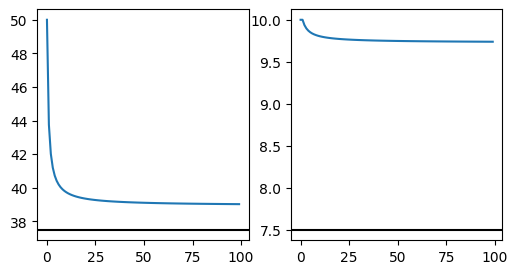

In [45]:
fig, ax = plt.subplots(1, 2, figsize = (6, 3))

ax[0].plot(dlu0[1:])
ax[0].axhline(h*W* (1 - 1/(h-1)), c = 'k') # aici ar tb sa tinda.

ax[1].plot(dsu0[1:])
ax[1].axhline(W * (1 - 1/(h-1)), c = 'k') # vr sa fie peste lim asta a.i. B_t = C[t-, su0, g, =] sa fie pozitiv.